# Setup

In [11]:
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import numpy as np
import pickle
from IPython.display import display


# Functions

## Misc

In [ ]:
def clean_path(path, server_map={"R730XD": "1248"}):
    if f"/mnt/{server_map['R730XD']}/" in path:
        return path
    parts = path.replace("\\", "/").lstrip("/").split("/")
    return Path("/mnt/" + "/".join([server_map[parts[0].upper()]] + parts[1:]))

In [13]:
def remove_duplicates(items):
    seen = set()
    result = []
    for item in items:
        if item not in seen:
            seen.add(item)
            result.append(item)
    return result

In [14]:
def add_LR(lst):
    newlist = []
    for i in lst:
        newlist.append("L_" + i)
        newlist.append("R_" + i)
    return newlist



## Database

In [28]:
len(df)

28

In [15]:
def databasecompile(g1, g2, metrics, general_label="", csv_labels=[]):
    
    database = pd.DataFrame(columns=["Regions", *metrics])
    
    # print(database)
    for region in csv_labels: # for each region
        if general_label != "":
            csv_name = f"{general_label}_{region}.csv"
            csv_name_reverse = f"{general_label}_{region}_reversedtermination.csv"
        else:
            csv_name = f"{region}.csv"
            csv_name_reverse = f"{region}_reversedtermination.csv"
            # if metrics == [] and general_label == "QSDR":
            #     metrics = ["qa", "qir", "vol", "dti_fa", "md", "rd", "iso", "rdi"]
            # elif metrics == "" and general_label == "DTI":
            #     metrics = ["fa", "md", "ad", "rd", "vol"]
        
        try:
            df1 = pd.read_csv(g1 / csv_name)
            df2 = pd.read_csv(g2 / csv_name)
        except FileNotFoundError:
            # print("notfound")
            continue

        try:
            df1r = pd.read_csv(g1 / csv_name_reverse)
            df2r = pd.read_csv(g2 / csv_name_reverse)
        except FileNotFoundError:
            # print("notfound")
            continue

        print(len(df1), len(df2), len(df1r), len(df2r))

        new_row = pd.Series(index=database.columns, dtype=object)

        new_row["Regions"] = region

        for metric in metrics: # for each metric
            data1 = df1[metric]
            data2 = df2[metric]

            new_row[metric] = pd.DataFrame(data=[data1, data2],index=["group1", "group2"])


        # print(new_row)

        if region in database["Regions"].values:
            # Get the index label of that row
            row_index = database[database["Regions"] == region].index[0]
            # Overwrite the entire row
            database.loc[row_index] = new_row
        else:
            # Append as a new row if not found
            database.loc[len(database)] = new_row

    # print(region)
    return database

## Statistics

In [16]:
def describe_groups(g1, g2, labels=("group1", "group2")):
    """n, median, and IQR per group."""
    rows = []
    for label, g in zip(labels, (g1, g2)):
        g = np.asarray(g, dtype=float)
        q1, med, q3 = np.percentile(g, [25, 50, 75])
        rows.append({"group": label, "n": len(g), "median": med,
                     "Q1": q1, "Q3": q3, "IQR": q3 - q1})
    return pd.DataFrame(rows).set_index("group")


def mwu_test(g1, g2, alternative="two-sided"):
    """U1, Umax, and p from the Mann-Whitney U test."""
    g1 = np.asarray(g1, dtype=float)
    g2 = np.asarray(g2, dtype=float)
    res = stats.mannwhitneyu(g1, g2, alternative=alternative)
    n1, n2 = len(g1), len(g2)
    u1 = res.statistic
    return {"U1": u1, "Umax": max(u1, n1 * n2 - u1), "p": res.pvalue}


def rank_biserial_ci(g1, g2, n_boot=5000, ci=95, seed=0):
    """Rank-biserial r (positive means group 1 tends higher) with a bootstrap CI."""
    g1 = np.asarray(g1, dtype=float)
    g2 = np.asarray(g2, dtype=float)
    n1, n2 = len(g1), len(g2)

    def rb(a, b):
        u = stats.mannwhitneyu(a, b).statistic
        return 2 * u / (len(a) * len(b)) - 1

    r = rb(g1, g2)
    rng = np.random.default_rng(seed)
    boot = [rb(rng.choice(g1, n1), rng.choice(g2, n2)) for _ in range(n_boot)]
    lo, hi = np.percentile(boot, [(100 - ci) / 2, 100 - (100 - ci) / 2])
    return {"r": r, "ci_low": lo, "ci_high": hi}


def run_mwu_report(g1, g2, labels=("group1", "group2"), n_boot=5000):
    """Run all three steps and print a compact report."""
    g1 = pd.to_numeric(pd.Series(g1), errors="coerce").dropna().to_numpy()
    g2 = pd.to_numeric(pd.Series(g2), errors="coerce").dropna().to_numpy()

    desc = describe_groups(g1, g2, labels)
    test = mwu_test(g1, g2)
    eff = rank_biserial_ci(g1, g2, n_boot=n_boot)

    # print("Descriptives")
    # print(desc.round(3).to_string())
    # print()
    # print(f"Mann-Whitney U: U1 = {test['U1']:.1f}, Umax = {test['Umax']:.1f}, p = {test['p']:.4f}")
    # print(f"Rank-biserial r = {eff['r']:.3f}, 95% CI [{eff['ci_low']:.3f}, {eff['ci_high']:.3f}]")
    # direction = labels[0] if eff["r"] > 0 else labels[1]
    # print(f"Direction: {direction} tends higher")

    return desc, test, eff

## Plot

In [17]:
def p_color(p):
    if p > 0.06:
        return "red"
    if p > 0.05:
        return "orange"
    if p > 0.01:
        return "green"
    return "darkgreen"

def plot_groups(g1, g2, labels=("group1", "group2"), title=None, ylabel=None, test=None, ax=None, p_threshold=1, ylim=None):
    """Box plot with individual points overlaid. Pass the dict from mwu_test to annotate U and p."""
    
    # skip if p value above threshold
    if test["p"] > p_threshold:
        return
    
    g1 = pd.to_numeric(pd.Series(g1), errors="coerce").dropna().to_numpy()
    g2 = pd.to_numeric(pd.Series(g2), errors="coerce").dropna().to_numpy()

    df = pd.DataFrame({
        "value": np.concatenate([g1, g2]),
        "group": [labels[0]] * len(g1) + [labels[1]] * len(g2),
    })

    if ax is None:
        fig, ax = plt.subplots(figsize=(4, 5))
        standalone = True
    else:
        standalone = False

    sns.boxplot(data=df, x="group", y="value", order=labels, showfliers=False,
                width=0.5, color="lightgray", ax=ax)
    sns.stripplot(data=df, x="group", y="value", order=labels, color="black",
                  alpha=0.5, size=3, jitter=0.15, ax=ax)

    if ylim is not None:
        ax.set_ylim(ylim)

    if test is not None:
        # Matplotlib titles take one color, so the stats line is a separate text
        # object placed just above the axes, and the title is pushed up to make room.
        ax.set_title(title or "", pad=20)
        ax.text(0.5, 1.01, f"U = {test['Umax']:.0f}, p = {test['p']:.3f}",
                transform=ax.transAxes, ha="center", va="bottom",
                color=p_color(test["p"]), fontweight="bold")
    else:
        ax.set_title(title or "")

    ax.set_xlabel("")
    ax.set_ylabel(ylabel if ylabel else "value")
    if standalone:
        plt.tight_layout()
    return ax


def plot_groups_grid(comparisons, ncols=3, panel_size=(4, 5), suptitle=None, p_threshold=1, ylim=None):
    # keep only comparisons that pass the threshold
    comparisons = [c for c in comparisons
                   if c.get("test") is None or c["test"]["p"] <= p_threshold]

    n = len(comparisons)
    if n == 0:
        return None, None
    ncols = min(ncols, n)
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(panel_size[0] * ncols, panel_size[1] * nrows),
                             squeeze=False)
    flat = axes.ravel()

    for ax, comp in zip(flat, comparisons):
        # grid-wide ylim is the default, a "ylim" key in the comparison overrides it
        plot_groups(ax=ax, **{"ylim": ylim, **comp})

    for ax in flat[n:]:
        ax.set_visible(False)

    if suptitle:
        fig.suptitle(suptitle, y=1.02)
    fig.tight_layout()
    return fig, axes

## Other

In [18]:
def batch_display_permetric(database, metric, g1_label, g2_label, columns = 4, cleanup_metric = "number of tracts", thresholds = (None,None), p_threshold = 1):
    tableformetric = pd.DataFrame(columns=columns)

    regions = database["Regions"].to_list()
    
    tableformetric["Regions"] = regions
    

    figdata = []

    for i in range(len(regions)):
        celldf = database[metric][i]
        # print(regions[i])
        # print(database[metric][i])
        
        # Thresholding
        if cleanup_metric != None:
            cleanupdf = database[cleanup_metric][i]
            if thresholds[0] == None:
                threshold_low = -np.inf
            else:
                threshold_low = thresholds[0]
            if thresholds[1] == None:
                threshold_high = np.inf
            else:
                threshold_high = thresholds[1]
        
            group1in = cleanupdf.columns[cleanupdf.loc["group1"].between(threshold_low, threshold_high, inclusive="both")].tolist()
            group2in = cleanupdf.columns[cleanupdf.loc["group2"].between(threshold_low, threshold_high, inclusive="both")].tolist()
            
            g1_values = []
            g1_values_all = pd.to_numeric(celldf.loc["group1"], errors="coerce")
            for j in group1in:
                g1_values.append(g1_values_all[j])
            
            g2_values = []
            g2_values_all = pd.to_numeric(celldf.loc["group2"], errors="coerce")
            for j in group2in:
                g2_values.append(g2_values_all[j])
        else:
            g1_values = pd.to_numeric(celldf.loc["group1"], errors="coerce").dropna()
            g2_values = pd.to_numeric(celldf.loc["group2"], errors="coerce").dropna()
        
        # print(regions[i])
        # print(g1_values)
        # print(g2_values)
        # desc, test, eff = run_mwu_report(g1_values, g2_values, labels=(g1_label, g2_label))

        test = mwu_test(g1_values, g2_values)
        eff = rank_biserial_ci(g1_values, g2_values)
        
        combdict = {"Regions": regions[i]} | test | eff

        regionrowidx = tableformetric.index[tableformetric["Regions"] == regions[i]][0]

        for column in columns:
            tableformetric.loc[regionrowidx, column] = combdict[column]
        
        figdata.append(
            dict(g1=g1_values, g2=g2_values, labels=(g1_label, g2_label), title=f"{metric}, {regions[i]}", ylabel=" ", test=test)
            )

    display(tableformetric)

    fig, axes = plot_groups_grid(figdata, ncols=4, p_threshold = p_threshold, 
                                #  ylim = (0, 250)
                                )

# Database Control

| Regions | Metric 1 | Metric 2 | ... |
| --- | --- | --- | --- |
| Region 1 | Ctrl values, Hydro_1 values | Ctrl values, Hydro_1 values | ... |
| Region 2 | Ctrl values, Hydro_1 values | Ctrl values, Hydro_1 values | ... |
| ... | ... | ... | ... |

## Compile

In [19]:
freesurfer_labels = (
    "CC_anterior", "CC_midanterior", "CC_central", "CC_midposterior", "CC_posterior",
)

hcpmmp_labels1 = add_LR([
    "3a", "3b", "1", "2",
    "6mp", "6ma", "SCEF",
    "5m", "5mv", "5L", "4",
    "24dd", "24dv", "23c", "p24pr",
    "6d", "6a", "6v", "6r", "55b",
    "46", "9-46d", "p9-46v", "a9-46v", "9a", "9p", "8C", "8Av", "8Ad", "i6-8", "s6-8",
    "47l", "47s", "47m", "a47r", "p47r", "45",
    "AAIC", "AVI", "MI", "FOP2", "FOP3",
    "PF", "PFt", "PFop", "PFm", "PFcm",
    "TPOJ1", "TPOJ2", "TPOJ3", "STV", "PSL",
    "7AL", "7Am", "7PC", "7PL", "7Pm", "7m", "VIP", "MIP", "LIPd", "LIPv", "AIP",
    "a24pr", "p24pr", "a32pr", "p32pr", "d32", "a24", "p24", "8BM",
    "9m", "10v", "10r", "25", "s32", "p32",
    "OFC", "pOFC", "11l", "13l",
    "SFL", "8BL", "8BM", "9m",
    "7m", "7Pm", "PCV", "POS2",
    "H", "PreS", "EC", "PeEc", "PHA1", "PHA2", "PHA3",
    "TGd", "TGv", "STGa", "TE1a",
    "TE1m", "TE1p", "TE2a", "TE2p", "PHT", "PH", "TF",
    "A4", "A5", "TA2", "STSda", "STSdp",
    "Ig", "PoI1", "PoI2", "PI", "52",
    "V1", "V2", "V3",
])

hcpmmp_labels2 = add_LR([
    "4", "3a", "3b", "1", "2", 
    "6mp", "6ma", "SCEF", "6d", "6v", 
    "24dd", "24dv", 
    "5m", "5mv", "5L", "7Am", "7Pm", "7PC", "7m", "VIP", "MIP", 
    "2v", "PIC", "OP2-3", "OP4", "PFcm", "43", 
    "46", "9-46d", "a9-46v", "p9-46v", "8C", "8Av", "8BL", "i6-8", "s6-8", "IFJa", "IFJp", "IFSa", "IFSp", "IP1", "IP2", "LIP", "AIP", "7PL", 
    "EC", "PreS", "H", "PeEc", "PHA1-3", "PHT", "PGp", "POS1", "POS2", "RSC", "v23ab", "d23ab", "31pv", "31pd", "31a", 
    "10r", "10v", "10d", "9m", "9a", "p32", "a24", "s32", "d32", "25", "47s", "PGi", "PGs", "TPOJ1-3", "STSdp", "STSvp", "TE1a", "TE1m", "TGd", 
    "44", "45", "47l", "55b", "PSL", "SFL", "STV", "A4", "A5", "TPOJ1"
])

hcpmmp_labels = add_LR([
    # 1. Primary
    "4", "3a", "3b", "1", "2",

    # 2. Premotor cortex
    "55b", "6d", "6v", "6a", "6r", "FEF", "PEF",

    # 3. Supplementary motor
    "6ma", "6mp", "SCEF", "24dd", "24dv",

    # 4. Prefrontal 
    "46", "9-46d", "a9-46v", "p9-46v", "9a", "9p", "9m", "8C", "8Av", "8Ad", "8BL", "8BM", "i6-8", "s6-8", "SFL", # (dorsolateral and dorsomedial)
    "44", "45", "IFJa", "IFJp", "IFSa", "IFSp", "47l", "p47r", "47m", "47s", # (inferior frontal)
    "a47r", "11l", "13l", "OFC", "pOFC", "10v", "10r", "10d", "10pp", "a10p", "p10p", # (orbital and polar)
    "25", "s32", "a24", "p24", "a24pr", "p24pr", "p32", "d32", "a32pr", "p32pr", "33pr", # (anterior cingulate and medial)

    # 5. Parietal
    "5m", "5mv", "5L", # (anterior)
    "7AL", "7Am", "7PL", "7Pm", "7PC", "LIPv", "LIPd", "VIP", "MIP", # (superior)
    "PF", "PFt", "PFop", "PFm", "PGi", "PGs", "PGp", "AIP", "IP0", "IP1", "IP2", # (inferior)
    "PFcm", "OP1", "OP2-3", "OP4", "43", "7m", "POS1", "POS2", "DVT", "PCV", "IPS1", # (related and opercular)

])

In [20]:
DTI_metrics = ["fa", "md", "ad", "rd", "vol"]
QSDR_metrics = ["qa", "qir", "vol", "dti_fa", "md", "rd", "iso", "rdi"]

cleanup_metrics = ["number of tracts"]

In [21]:
group1 = r"\\R730XD\open\finley\hydrocephalus\Ctrl"
group2 = r"\\R730XD\open\finley\hydrocephalus\Hydro_1"

# output_dir = r"\\R730XD\open\finley\hydrocephalus\statistics\MannWhitneyU"

general_label = "QSDRfinal"

csv_labels = remove_duplicates([
    # *freesurfer_labels,
    *hcpmmp_labels

    ])

metrics = QSDR_metrics + cleanup_metrics

In [22]:
newdatabase = databasecompile(g1 = clean_path(group1), 
                           g2 = clean_path(group2), 
                           metrics = metrics, 
                           general_label = general_label, 
                           csv_labels = csv_labels
                           )

In [23]:
database = newdatabase
display(database)

,Regions,qa,qir,vol,dti_fa,md,rd,iso,rdi,number of tracts


## Export

In [14]:
database_folderpath_export = "/mnt/1248/open/finley"
database_filename_export = "QSDRfinal"

In [15]:
with open((Path(database_folderpath_export) / (database_filename_export + ".pkl")), "wb") as f:
    pickle.dump(newdatabase, f)

## Import

In [18]:
database_folderpath_import = "/mnt/1248/open/finley"
database_filename_import = "database1"

In [19]:
try:
    with open((Path(database_folderpath_import) / (database_filename_import + ".pkl")), "rb") as f:
        database = pickle.load(f)
    display(database)
except FileNotFoundError:
    print("File not found.")
    database = None


,Regions,qa,qir,vol,dti_fa,md,rd,iso,rdi
0,CC_anterior,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...
1,CC_midanterior,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...
2,CC_central,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...
3,CC_midposterior,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...
4,CC_posterior,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...
...,...,...,...,...,...,...,...,...,...
230,R_V1,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...
231,L_V2,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...
232,R_V2,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...
233,L_V3,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...,0 1 2 3 ...


In [ ]:
database["number of tracts"].loc[0]

,0,1,2,3,4,5,6,7,8,9,...,12,13,14,15,16,17,18,19,20,21
group1,14.0,1.0,1390.0,38.0,10.0,1.0,56.0,2418.0,122.0,57.0,...,7.0,475.0,536.0,170.0,2.0,40.0,2326.0,124.0,981.0,5.0
group2,1.0,1.0,19.0,98.0,35.0,25.0,4.0,32.0,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Mann Whitney U Test

## Single

In [82]:
region = "R_IFJp"
metric = "rd"

g1_label = "Ctrl"
g2_label = "Hydro_1"

database[metric][database.index[database['Regions'] == region][0]]

,0,1,2,3,4,5,6,7,8,9,...,27,28,29,30,31,32,33,34,35,36
group1,0.607005,0.585194,0.530049,0.668270,0.618227,0.655604,0.525795,0.542779,0.537898,0.643786,...,0.549401,0.555613,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
group2,0.641231,0.847964,0.551320,0.553173,0.473337,0.684113,0.532637,0.703038,0.693469,0.595658,...,0.727275,0.924003,0.909576,0.848451,0.719504,0.484378,0.619769,0.548842,0.867538,0.532773


<Axes: title={'center': 'rd, R_IFJp'}, ylabel='rd'>

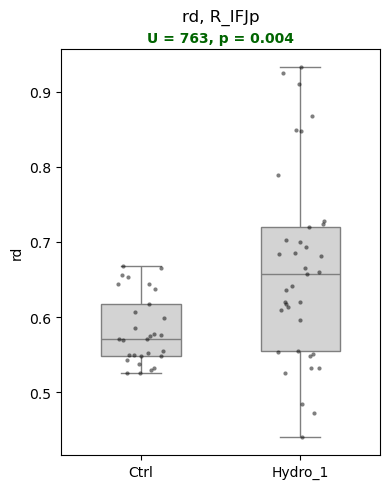

In [83]:
regionindex = database.index[database['Regions'] == region][0]
celldf = database[metric][regionindex]

g1_values = pd.to_numeric(celldf.loc["group1"], errors="coerce").dropna()
g2_values = pd.to_numeric(celldf.loc["group2"], errors="coerce").dropna()

desc, test, eff = run_mwu_report(g1_values, g2_values, labels=(g1_label, g2_label))

plot_groups(g1_values, g2_values, labels=(g1_label, g2_label),
            title=f"{metric}, {region}", ylabel=metric, test=test)

## Generate Test Result Table and Figures for Each Metric

Metric comparison between Ctrl and Hydro_1
| Regions | U1 | Umax | p | Rank-biserial r |
| --- | --- | --- | --- | --- |
| Region 1 | ... | ... | ... | ... |
| Region 2 | ... | ... | ... | ... |
| ... | ... | ... | ... | ... |

In [16]:
regions = csv_labels
metric = "dti_fa"

cleanup_metric = "number of tracts"
thresholds = [100, None]

p_threshold = 1

g1_label = "Ctrl"
g2_label = "Hydro_1"

columns = ["Regions", "U1", "Umax", "p", "r"]

/tmp/ipykernel_82420/3124274478.py:16: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  res = stats.mannwhitneyu(g1, g2, alternative=alternative)
/tmp/ipykernel_82420/3124274478.py:29: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  u = stats.mannwhitneyu(a, b).statistic
/tmp/ipykernel_82420/3124274478.py:16: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  res = stats.mannwhitneyu(g1, g2, alternative=alternative)
/tmp/ipykernel_82420/3124274478.py:29: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  u = stats.mannwhitneyu(a, b).statistic
/tmp/ipykernel_82420/3124274478.py:16: SmallSampleWarning: One or 

,Regions,U1,Umax,p,r
0,L_4,144.0,144.0,0.017788,0.565217
1,R_4,62.0,62.0,0.140351,0.458824
2,L_3a,8.0,8.0,0.222222,1.0
3,R_3a,17.0,17.0,0.811189,0.133333
4,L_3b,11.0,11.0,0.625,0.466667
...,...,...,...,...,...
89,R_13l,NaN,NaN,NaN,NaN
90,L_OFC,NaN,NaN,NaN,NaN
91,R_OFC,NaN,NaN,NaN,NaN
92,L_pOFC,NaN,NaN,NaN,NaN


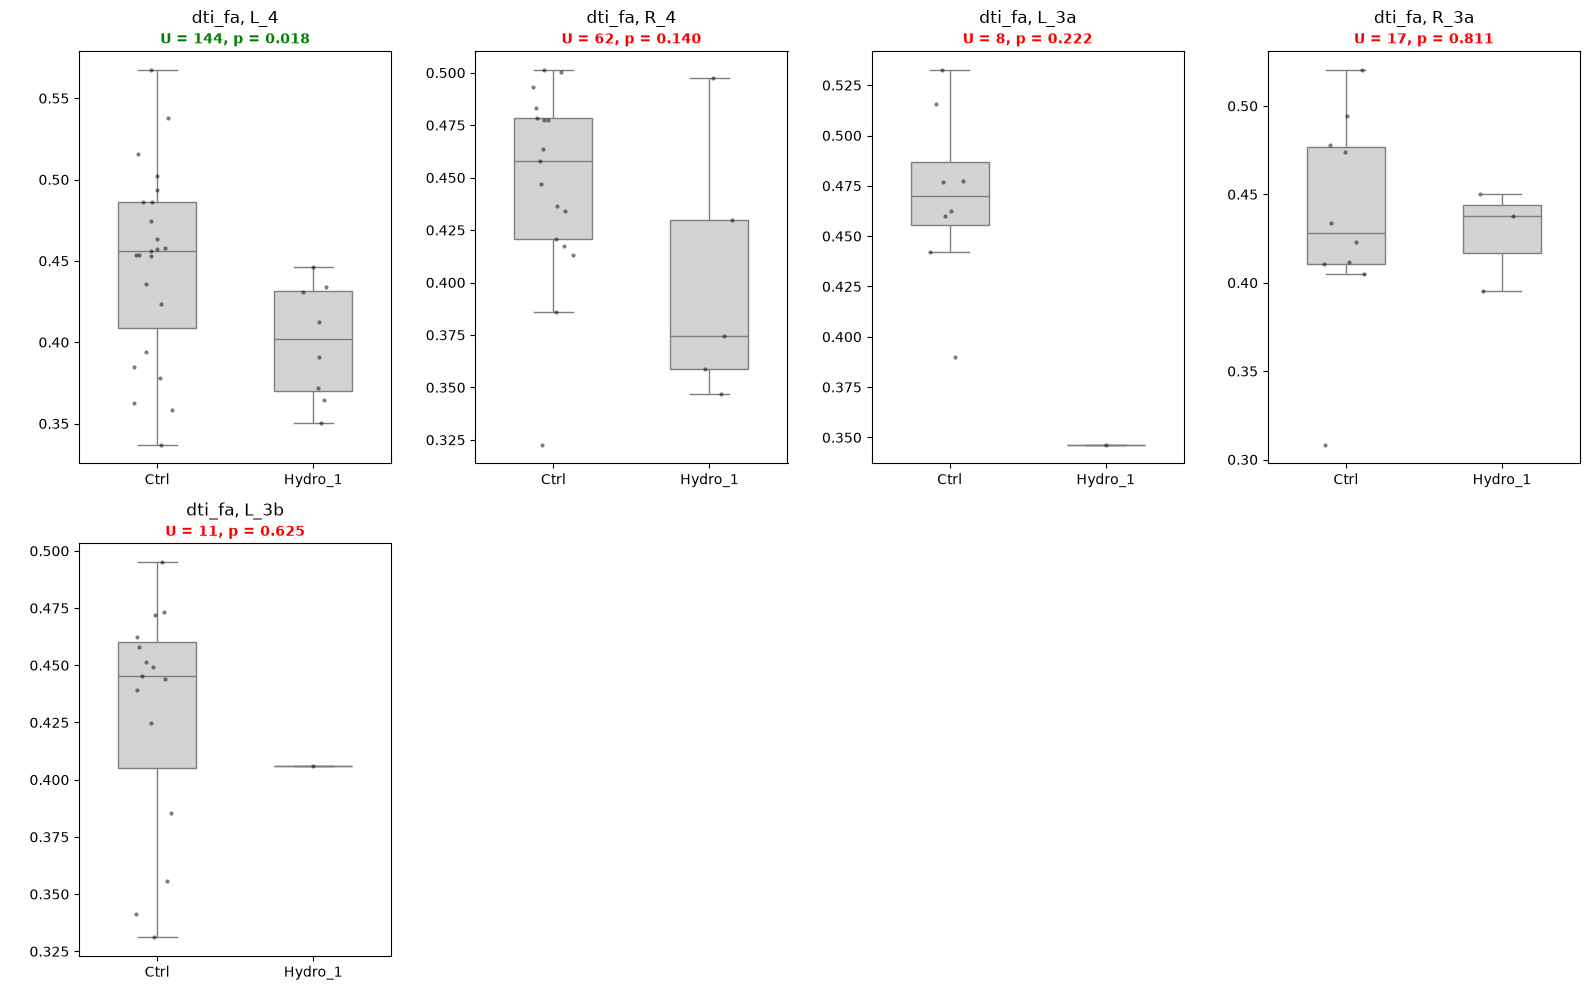

In [17]:
batch_display_permetric(database = database, 
                        metric = metric, 
                        g1_label = g1_label,
                        g2_label = g2_label,
                        columns = columns, 
                        cleanup_metric = cleanup_metric, 
                        thresholds = thresholds,
                        p_threshold = p_threshold,
                        )

# Correlational Tractography

## Cleanup

# Export

In [23]:
save_variable = database
folderpath = Path("/mnt/1248/open/finley")
filename = "database1"

with open((folderpath / (filename + ".pkl")), "wb") as f:
    pickle.dump(save_variable, f)



In [ ]:
filename = "database1"

with open((folderpath / (filename + ".pkl")), "rb") as f:
    openvar = pickle.load(f)

In [196]:
export_folder = "/mnt/1248/open/finley/hydrocephalus"
export_name = "QSDR_qa"

df = tableformetric

df.to_csv((Path(export_folder)/export_name), index=False)

In [197]:
newdf = pd.read_csv(Path(export_folder)/export_name)

In [198]:
newdf

,Regions,U1,Umax,p,r
0,CC_anterior,919.0,919.0,8.001290e-07,0.712954
1,CC_midanterior,982.0,982.0,8.962491e-09,0.830382
2,CC_central,1021.0,1021.0,4.022601e-10,0.903075
3,CC_midposterior,1015.0,1015.0,6.590022e-10,0.891892
4,CC_posterior,886.0,886.0,6.513852e-06,0.651445
...,...,...,...,...,...
230,R_V1,396.0,677.0,7.048800e-02,-0.261883
231,L_V2,444.0,629.0,2.345912e-01,-0.172414
232,R_V2,616.0,616.0,3.074163e-01,0.148183
233,L_V3,563.0,563.0,7.369365e-01,0.049394


# tests


In [3]:
df = pd.read_csv(Path("/mnt/1248/open/finley/hydro_combined.tsv"), sep="\t")

In [4]:
df

,ID,Age,Gender,Base_TUG,Base_POMA_Bal,Base_POMA_Gait,Base_POMA_Tot,Base_MMSE,Base_MOCA,Shunt_TUG,Shunt_POMA_Bal,Shunt_POMA_Gait,Shunt_POMA_Tot,Shunt_MMSE,Shunt_MOCA
0,5694483,77,Male,17.72,NaN,NaN,NaN,27.0,NaN,9.17,NaN,NaN,NaN,25.0,20.0
1,6847059,73,Male,20.30,NaN,NaN,NaN,16.0,13.0,19.00,14.0,8.0,22.0,20.0,14.0
2,5259416,76,Male,NaN,NaN,NaN,NaN,17.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN
3,7340788,80,Female,19.00,NaN,NaN,NaN,20.0,14.0,12.18,16.0,11.0,27.0,28.0,16.0
4,7379648,72,Male,16.10,13.0,9.0,22.0,18.0,14.0,14.67,15.0,10.0,25.0,NaN,NaN
5,4263333,75,Female,NaN,NaN,NaN,NaN,23.0,11.0,20.55,11.0,9.0,20.0,27.0,14.0
6,721057,78,Male,17.04,NaN,NaN,NaN,27.0,20.0,12.00,16.0,11.0,27.0,NaN,NaN
7,6767874,72,Male,NaN,0.0,NaN,0.0,9.0,NaN,32.82,13.0,9.0,22.0,NaN,NaN
8,3803343,73,Male,13.70,NaN,NaN,NaN,23.0,16.0,11.83,16.0,11.0,27.0,23.0,18.0
9,1894906,75,Female,80.00,10.0,2.0,12.0,NaN,NaN,60.00,NaN,NaN,NaN,NaN,NaN


In [9]:
df.to_csv(Path("/mnt/1248/open/finley/hydro_combined.csv"), index=False)